# Supervised Learning & Model Engineering - Group project
# STEP 8: Diagnostics and explainability of the final model

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Eliott, reviewed by all)
**Course reference:** Session 8 (slice-based evaluation, error analysis, gain vs permutation importance, SHAP global and local, partial dependence, "SHAP is not causal", model card)
**Code:** `src/explain.py`. Settings: `config.yaml`, section `explain`. Results: `reports/explain/`. Tests: `tests/test_explain.py`.

### How to read this notebook
Same labels as the previous steps: **What we see**, **What we decide**, **What could invalidate it**, **Limitation**.

### The questions (requirement 8 + Session 8)
A good global score (PR-AUC 0.763) does not say **where the model fails** nor **what drives it**. Session 8 answers with two families of tools:
1. **Diagnostics** (Part B): performance by meaningful group of people, then a look at the errors of the weakest group.
2. **Explainability** (Parts C to F): which features the model relies on (gain, permutation, SHAP), why one person got their probability (SHAP waterfall), and what average relationship the model learned (PDP).

### The rule of this step
The model is the **frozen final model of STEP 6** (LightGBM, threshold 0.15), rebuilt identically. The test set is used to **describe** the model, as in the Session 8 notebook; nothing is chosen or changed here.

### How to run
`python -m src.explain` (about 2 minutes, mostly the 20 shuffles of permutation importance). This notebook runs the same code.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.inspection import PartialDependenceDisplay

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config
from src.explain import run_explain, save_results, shap_by_category, local_table

warnings.filterwarnings("ignore")
cfg = load_config()
FIG_DIR = cfg["paths"]["figures_dir"]
sns.set_theme(style="whitegrid")

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

r = run_explain(cfg)              # rebuilds the frozen final model of STEP 6 (about 2 minutes)
save_results(cfg, r)
print(f"Final model: {cfg['final']['model']}, threshold {r['threshold']:.2f}, test set: {len(r['y']):,} people")

/home/claude/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Final model: lightgbm, threshold 0.15, test set: 9,758 people


---
# Part B - Where does the model fail? (slice-based evaluation)

Session 8: a global score can hide a group where the model performs badly. We cut the test set into **meaningful groups** for the bank (age, diploma, marital status, working hours, sex) and recompute the same metrics in each one. Next to each metric we show the size of the group and its share of wealthy people (prevalence), because PR-AUC depends on the prevalence and a small group gives noisy numbers.

**Which metric decides "weakest"?** Session 8: it depends on the business decision. For the bank a missed wealthy prospect costs 5 useless calls (STEP 4), so the metric that matters is the **recall** (share of wealthy people found). Groups with fewer than 100 wealthy people are shown but not used to name the weakest group.

,n,prevalence,wealthy,found,missed,precision,recall,pr_auc
slice,,,,,,,,
All,9758,23.9%,2336,2143,193,50.6%,91.7%,0.763
age 17-25,1910,2.4%,45,21,24,42.0%,46.7%,0.380
age 26-35,2475,18.0%,445,398,47,41.2%,89.4%,0.669
age 36-45,2401,35.2%,845,796,49,54.6%,94.2%,0.800
age 46-55,1676,37.1%,622,586,36,54.1%,94.2%,0.810
age 56-65,913,32.9%,300,273,27,52.4%,91.0%,0.755
age 66+,383,20.6%,79,69,10,43.4%,87.3%,0.615
education: no high-school diploma,1292,5.8%,75,38,37,30.2%,50.7%,0.352
education: high-school graduate,3115,16.1%,500,430,70,36.4%,86.0%,0.529


Weakest slice for our decision (lowest recall, at least 100 wealthy people): not married


Figure saved: reports/figures/24_performance_by_slice.png


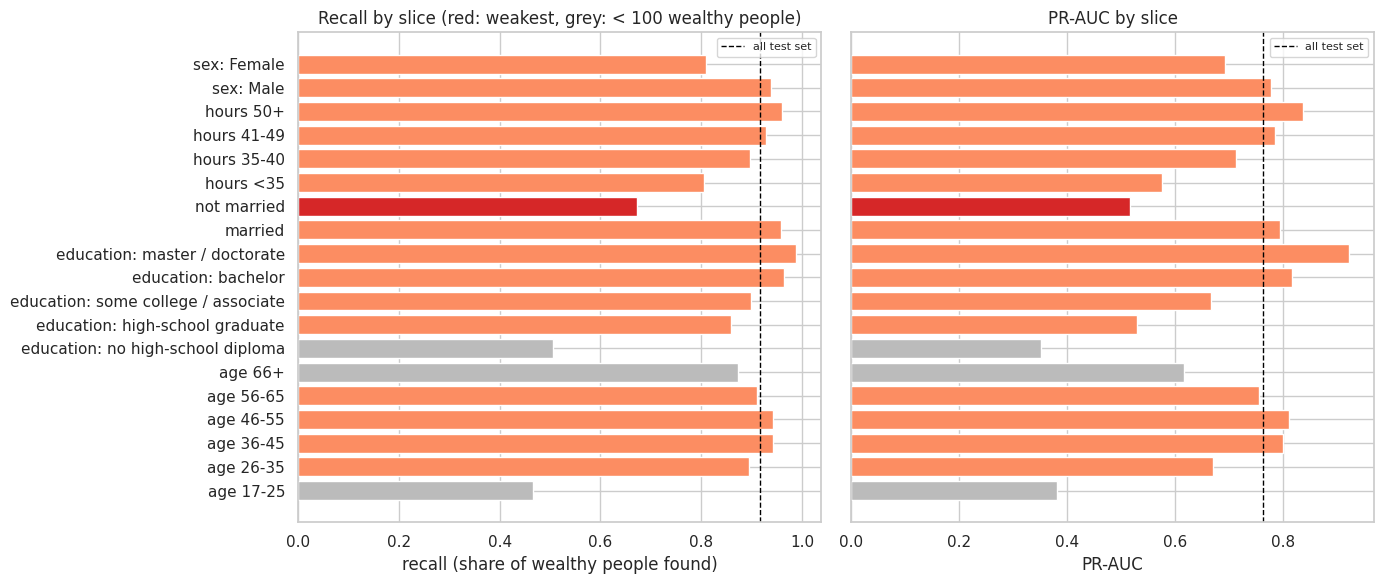

In [2]:
# ===================== B.1 Performance by slice (test set, threshold 0.15) =====================
cols = ["n", "prevalence", "wealthy", "found", "missed", "precision", "recall", "pr_auc"]
display(r["slices"][cols].style.format({"prevalence": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}", "pr_auc": "{:.3f}"})
        .background_gradient(subset=["recall"], cmap="RdYlGn", vmin=0.4, vmax=1.0))
print(f"Weakest slice for our decision (lowest recall, at least {cfg['explain']['min_wealthy_per_slice']} wealthy people): {r['weakest']}")

t = r["slices"].drop(index="All")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, metric, label in [(axes[0], "recall", "recall (share of wealthy people found)"), (axes[1], "pr_auc", "PR-AUC")]:
    colors = ["#d62728" if s == r["weakest"] else ("#bbbbbb" if t.loc[s, "wealthy"] < cfg["explain"]["min_wealthy_per_slice"] else "#fc8d62")
              for s in t.index]
    ax.barh(t.index, t[metric], color=colors)
    ax.axvline(r["slices"].loc["All", metric], color="black", ls="--", lw=1, label="all test set")
    ax.set_xlabel(label); ax.invert_yaxis(); ax.legend(fontsize=8)
axes[0].set_title("Recall by slice (red: weakest, grey: < 100 wealthy people)"); axes[1].set_title("PR-AUC by slice")
savefig("24_performance_by_slice")
plt.show()

**What we see.**
- **Not married** people are the weakest group: **recall 67%** (224 of 333 wealthy found, 109 missed), against 96% for married people. This single group holds **109 of the 193 missed wealthy people (56%)**, while it contains only 14% of the wealthy people.
- The PR-AUC follows the prevalence: 0.52 for not married (6.3% wealthy), 0.92 for master / doctorate (63% wealthy). Session 8 warns that PR-AUC must be read with the prevalence: a lower PR-AUC in a group with few wealthy people is partly expected.
- Very low recall also for **17-25 year olds** (47%) and **people without a high-school diploma** (51%), but with only 45 and 75 wealthy people: too few to conclude (grey bars).
- Women: recall 81% vs 94% for men. In the test set 85% of women are not married, against 38% of men, so this gap is largely the same weakness seen from another angle. (Here `sex` is only a diagnostic slice. The fairness audit itself, with a fairness definition and a mitigation, is STEP 9 (requirement 10).)

**What we decide.** The weakest meaningful segment is **not married people** (decision 50). It is named in the model card (Part H), as Session 8 requires.

## B.2 Error analysis: who are the wealthy people the model misses?

In [3]:
# ===================== B.2 Error analysis inside the weakest slice =====================
display(r["errors"].style.format({"n": "{:.0f}", "mean age": "{:.1f}", "mean years of education": "{:.1f}",
                                  "mean hours per week": "{:.1f}", "share with a capital gain": "{:.0%}",
                                  "share manager or professional": "{:.0%}", "share women": "{:.0%}",
                                  "mean predicted probability": "{:.1%}"}))

,n,mean age,mean years of education,mean hours per week,share with a capital gain,share manager or professional,share women,mean predicted probability
wealthy found,224,44.8,13.1,48.7,42%,76%,37%,45.4%
wealthy missed,109,42.7,10.4,40.9,13%,28%,48%,7.0%


**What we see** (not married, wealthy people only).
- Missed wealthy people have **fewer years of education** (10.4 vs 13.1, i.e. high-school level instead of bachelor), **work fewer hours** (40.9 vs 48.7), are **rarely managers or professionals** (28% vs 76%) and **rarely have a capital gain** (13% vs 42%).
- The model gives them on average **7%**, far below the threshold of 15%.

**Interpretation.** For a not-married person the model has no "married" signal to rely on (Part D shows it is one of the strongest), so it needs the other signals: diploma, occupation, hours, capital. Wealthy single people with an ordinary profile on these signals look like the majority of single people, who are not wealthy (only 6.3% of them are). The information that would separate them (exact income sources, wealth) is not in the census data.

**What could fix it** (not done here, to keep the frozen model): a lower threshold for this group would find more of them but would multiply useless calls (94% of single people are not wealthy). We report the weakness instead of hiding it.

---
# Part C - Which features does the model rely on? Gain vs permutation (Session 8)

Two importances, two questions (Session 8):
- **Gain importance**: how much each input improved the training objective inside LightGBM's trees. Computed during training, on the model inputs.
- **Permutation importance**: how much the PR-AUC **drops on the test set** when one column is shuffled and the others are kept. It measures how much the fitted model **needs** that information on new data. We shuffle the **raw columns** given to the Pipeline, so the check includes columns the Pipeline drops.

Figure saved: reports/figures/25_gain_vs_permutation_importance.png


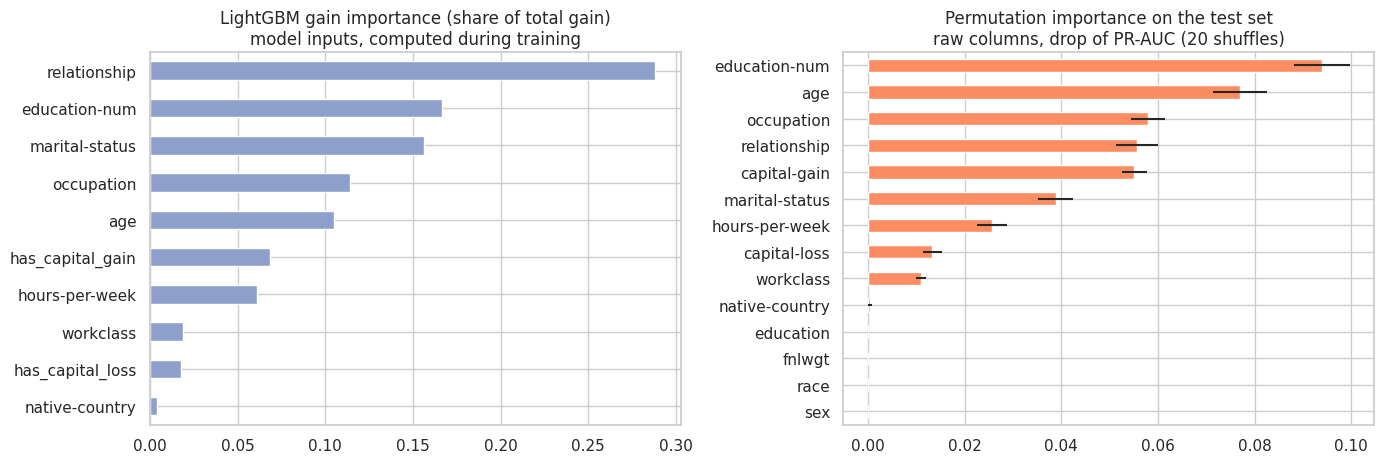

,gain rank,permutation rank
relationship,1,4
education-num,2,1
marital-status,3,6
occupation,4,3
age,5,2
has_capital_gain,6,5
hours-per-week,7,7
workclass,8,9
has_capital_loss,9,8
native-country,10,10


In [4]:
# ===================== C. Gain importance vs permutation importance =====================
gain, perm = r["gain"], r["perm"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
gain.sort_values().plot.barh(ax=axes[0], color="#8da0cb")
axes[0].set_title("LightGBM gain importance (share of total gain)\nmodel inputs, computed during training")
perm["pr_auc_drop"].sort_values().plot.barh(ax=axes[1], xerr=perm["std"].sort_values().reindex(perm["pr_auc_drop"].sort_values().index),
                                            color="#fc8d62")
axes[1].set_title("Permutation importance on the test set\nraw columns, drop of PR-AUC (20 shuffles)")
savefig("25_gain_vs_permutation_importance")
plt.show()
display(pd.DataFrame({"gain rank": gain.rank(ascending=False).astype(int)}).join(
    perm["pr_auc_drop"].rank(ascending=False).astype(int).rename("permutation rank")
      .rename(index={"capital-gain": "has_capital_gain", "capital-loss": "has_capital_loss"})).sort_values("gain rank"))

**What we see.**
- **Permutation**: `education-num` (-0.094 PR-AUC), `age` (-0.077), `occupation` (-0.058), `relationship` (-0.056), `capital-gain` (-0.055) matter most. `native-country` and `workclass` matter very little.
- **`sex`, `race`, `fnlwgt`, `education`: exactly 0.** Shuffling them changes nothing, because the Pipeline removes them (decisions 3, 4, 8). This is a direct proof on the final model that it does not use `sex` or `race`.
- **Gain** ranks `relationship` first (29% of the total gain), but permutation ranks it 4th. Session 8 explains this kind of disagreement: `relationship` and `marital-status` carry almost the same information (a "Spouse" is "Married-civ-spouse"). When one is shuffled, the model still finds the information in the other, so each one alone looks less important. Together they are the strongest signal.

**What we decide.** We use permutation importance for the ranking we report (it is measured on new data, with our metric), and we read `relationship` + `marital-status` as **one household signal**.

---
# Part D - SHAP: global view (Session 8)

SHAP splits each prediction into a **baseline** plus **one contribution per feature**: a positive value pushes towards >50K, a negative value away from it. **Scale (Session 8 warning):** for LightGBM, SHAP explains the raw score in **log-odds**, not the probability; probability = sigmoid(baseline + sum of contributions). The global importance is the **average size** of the contributions, mean |SHAP|.

Check: base value + sum of SHAP values = raw score, max error 1.8e-14
Base value (average raw score, log-odds) = -2.22
Figure saved: reports/figures/26_shap_global_importance.png


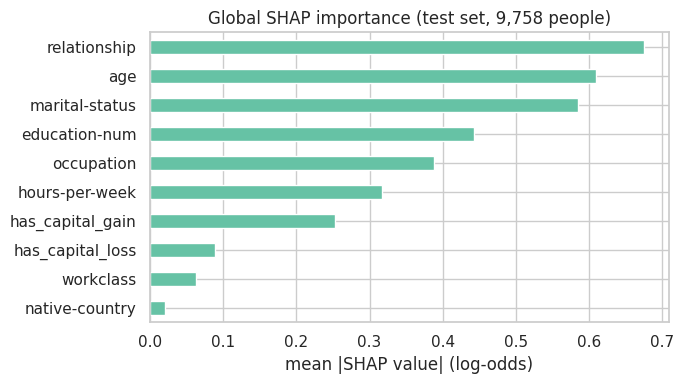

Figure saved: reports/figures/27_shap_beeswarm_numerical.png


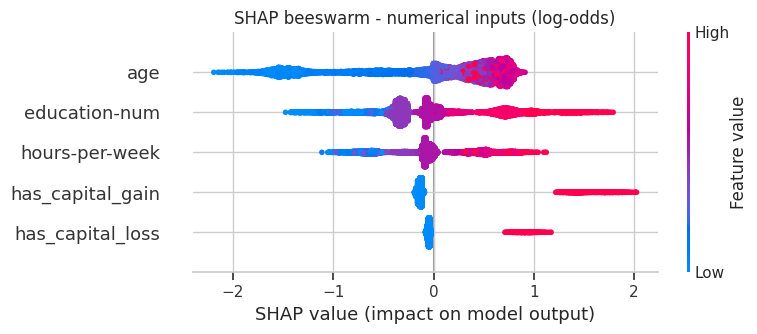

Mean SHAP value per category - relationship


,mean SHAP,n
relationship,,
Spouse,+0.74,4405
Not-in-family,-0.38,2548
Other-relative,-0.79,301
Own-child,-0.83,1486
Unmarried,-0.86,1018


Mean SHAP value per category - marital-status


,mean SHAP,n
marital-status,,
Married-civ-spouse,+0.64,4472
Married-spouse-absent,-0.16,124
Married-AF-spouse,-0.17,8
Widowed,-0.23,324
Divorced,-0.48,1338
Separated,-0.52,329
Never-married,-0.62,3163


Mean SHAP value per category - occupation


,mean SHAP,n
occupation,,
Exec-managerial,+0.63,1214
Prof-specialty,+0.52,1262
Protective-serv,+0.45,181
Tech-support,+0.37,276
Sales,+0.21,1083
Craft-repair,-0.03,1221
Transport-moving,-0.16,481
Adm-clerical,-0.16,1128
Missing,-0.31,579


In [5]:
# ===================== D. Global SHAP =====================
values, Z, readable = r["shap_values"], r["Z"], r["readable"]
print(f"Check: base value + sum of SHAP values = raw score, max error {r['additivity_error']:.1e}")
print(f"Base value (average raw score, log-odds) = {r['base']:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
r["shap_importance"].sort_values().plot.barh(ax=ax, color="#66c2a5")
ax.set_xlabel("mean |SHAP value| (log-odds)"); ax.set_title("Global SHAP importance (test set, 9,758 people)")
savefig("26_shap_global_importance")
plt.show()

# Beeswarm for the numerical inputs (colour = feature value; for categories a colour would be a code, not a value)
num = ["age", "education-num", "hours-per-week", "has_capital_gain", "has_capital_loss"]
idx = [list(Z.columns).index(c) for c in num]
shap.summary_plot(values[:, idx], Z[num], show=False)
plt.title("SHAP beeswarm - numerical inputs (log-odds)")
savefig("27_shap_beeswarm_numerical")
plt.show()

for col in ["relationship", "marital-status", "occupation"]:
    print(f"Mean SHAP value per category - {col}")
    display(shap_by_category(values, readable, col).style.format({"mean SHAP": "{:+.2f}"}))

**What we see.**
- Check: the contributions add up exactly to the model's raw score (max error about 1e-14). The baseline is -2.22 in log-odds (about 10%).
- **Global ranking**: `relationship` (0.68), `age` (0.61), `marital-status` (0.59), `education-num` (0.44), `occupation` (0.39), `hours-per-week` (0.32), `has_capital_gain` (0.25). The same top group as permutation, with the household signal first (as in gain).
- **Beeswarm (directions)**: more years of education push up; long hours push up; having a capital gain or loss pushes up; young age pushes strongly down (down to -2.2), and from mid-career on age pushes up.
- **Categories**: `Spouse` +0.74 vs `Own-child` -0.83 and `Unmarried` -0.86; `Married-civ-spouse` +0.64 vs `Never-married` -0.62; `Exec-managerial` +0.63 and `Prof-specialty` +0.52 vs `Other-service` -0.67 and `Farming-fishing` -0.66.

**Do the drivers make business sense?** Yes, they are the classic determinants of income: **age and career stage, education, type of job, working time, owning investments**. The household signal is the least obvious one. In the 1994 census, married people are mostly in mid-career and, for the married men who form most of this group, the household's main earner. So the model uses "married" as a summary of life stage and household role.

**Limitation (Session 8: SHAP is not causal).** "Being married raises the prediction" is a statement **about the model**, not "getting married raises income". And `relationship` stays a partial proxy for sex (STEP 2): in the `Spouse` category, about 9 people in 10 are husbands.

---
# Part E - SHAP: local explanations for three people

Three people picked by a **fixed rule**, not by hand: a clear call (wealthy, predicted close to 90%), the borderline call (just above the 0.15 threshold), and a missed wealthy person from the weakest slice (median probability of those misses). Each waterfall starts from the baseline and adds each feature's contribution (log-odds).


clear call (wealthy, ~90%): P(>50K) = 89.9%, decision = call, truth = >50K


Figure saved: reports/figures/28_shap_waterfall_clear_call.png


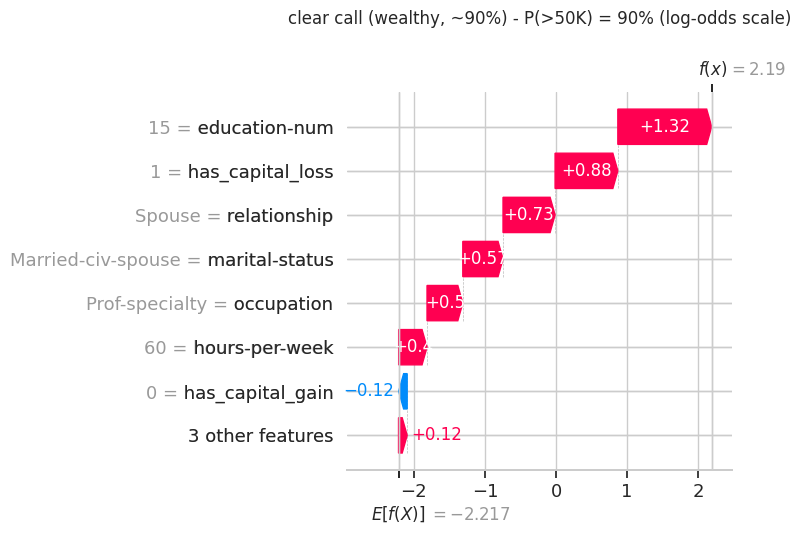


borderline call (just above 0.15): P(>50K) = 15.0%, decision = call, truth = >50K


Figure saved: reports/figures/28_shap_waterfall_borderline_call.png


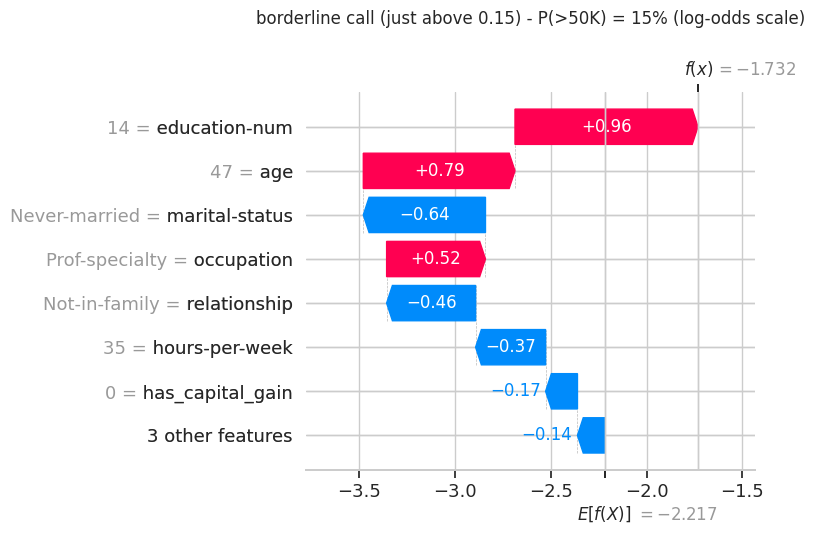


missed wealthy person (weakest slice): P(>50K) = 6.4%, decision = no call, truth = >50K


Figure saved: reports/figures/28_shap_waterfall_missed_wealthy_person.png


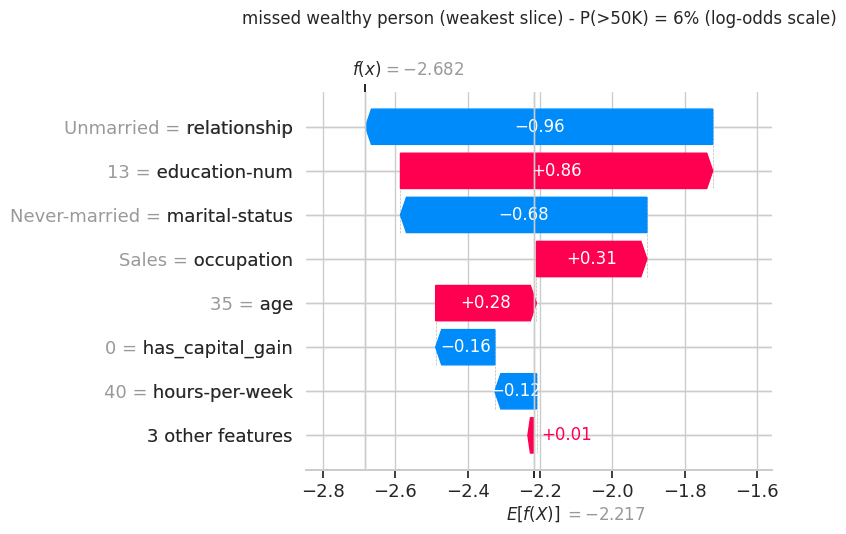

In [6]:
# ===================== E. Local SHAP: three people explained =====================
for name, i in r["cases"].items():
    p, y_i = r["proba"][i], r["y"][i]
    print(f"\n{name}: P(>50K) = {p:.1%}, decision = {'call' if p >= r['threshold'] else 'no call'}, "
          f"truth = {'>50K' if y_i == 1 else '<=50K'}")
    expl = shap.Explanation(values=values[i], base_values=r["base"], data=readable.iloc[i].values,
                            feature_names=list(readable.columns))
    shap.plots.waterfall(expl, max_display=8, show=False)
    plt.title(f"{name} - P(>50K) = {p:.0%} (log-odds scale)", pad=25)
    savefig("28_shap_waterfall_" + name.split(" (")[0].replace(" ", "_"))
    plt.show()

**What we see.**
- **Clear call (90%, wealthy):** master-level education (15 years, +1.32), a capital loss (+0.88), married `Spouse` (+0.73 and +0.57), professional occupation (+0.50), 60 hours a week (+0.40). Every major signal points the same way.
- **Borderline call (15.0%, wealthy):** strong positives (master's level, +0.96; age 47, +0.79; professional, +0.52) are almost cancelled by negatives (never married, -0.64; not in family, -0.46; 35 hours, -0.37). The person lands exactly at the threshold: called, and indeed wealthy.
- **Missed wealthy person (6.4%, not married):** a bachelor's degree (+0.86) and a sales job (+0.31) push up, but `Unmarried` (-0.96) and `Never-married` (-0.68) pull down more. This is the pattern of Part B, seen on one person.

**What it brings to the bank.** An advisor can see **why** a prospect is on the list ("master's degree, senior professional, long hours") and why another is not. For the missed prospect, the explanation shows that the household signal outweighed a good diploma: useful to explain the model's limits, not a reason to change one person's decision.

---
# Part F - Partial dependence: what average relationship did the model learn? (Session 8)

The PDP sets one feature to the same value for everyone (here 2,000 development rows), keeps the other features as they are, and averages the predicted probability; then it repeats for each value. It shows the **shape** of the effect learned by the model, on the probability scale.

Figure saved: reports/figures/29_partial_dependence.png


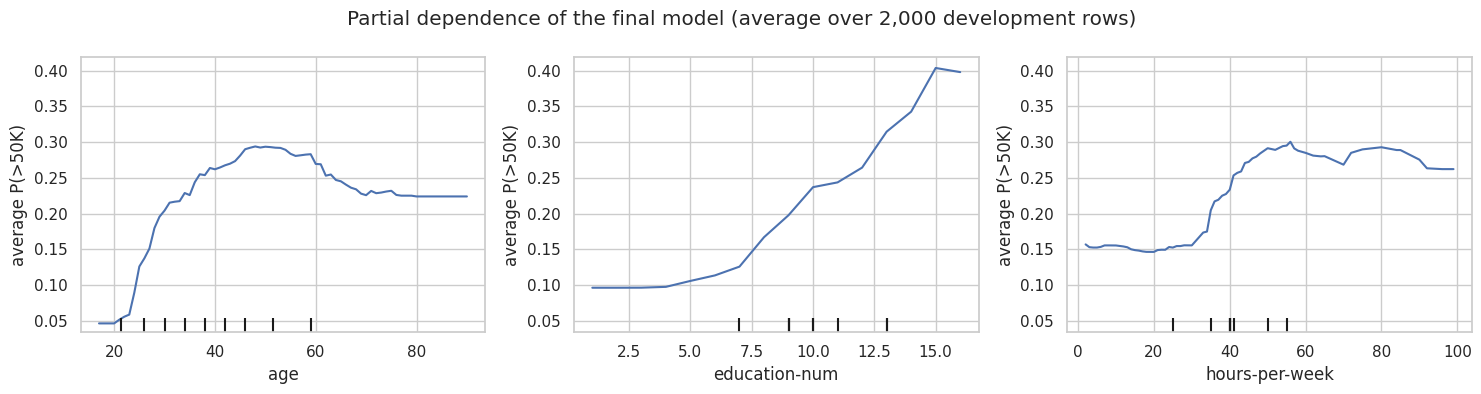

In [7]:
# ===================== F. Partial dependence (development sample) =====================
from src.data import load_splits
X_dev, _, _, _ = load_splits(cfg)
sample = X_dev.sample(cfg["explain"]["pdp_sample"], random_state=cfg["seed"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(r["pipe"], sample, features=cfg["explain"]["pdp_features"], kind="average", ax=ax)
for a in ax: a.set_ylabel("average P(>50K)")
fig.suptitle("Partial dependence of the final model (average over 2,000 development rows)")
savefig("29_partial_dependence")
plt.show()

**What we see.**
- **Age:** the average probability rises from about 5% at 17-22 to a peak of about **29% around 47-52**, then decreases slowly to about 22% after 75. The **bell curve** found in the STEP 1 EDA and handled with bands for the linear model in STEP 2: LightGBM learned it by itself, as expected for trees.
- **Education:** flat around 10% up to 7 years, then a steady rise from high school (9 years, 20%) to bachelor (13, 32%) and master / doctorate (15-16, about 40%).
- **Hours per week:** flat around 15% below 30 hours, rising from 35 to 50 hours (up to about 29%), then flat.

**Limitation (Session 8).** The PDP keeps the other features unchanged, so it can create unrealistic people (for example 17 years old with a doctorate). Read it as the model's average behaviour, not as the effect of changing a person's age or diploma.

---
# Part G - Answer to requirement 8

**Global importance.** Permutation importance on the test set: education, age, occupation, relationship and capital gain lead. SHAP gives the same top group, with the household signal (`relationship` + `marital-status`) first. `sex`, `race`, `fnlwgt` and `education` have exactly zero importance: the Pipeline removes them.

**Local explanations.** SHAP waterfalls explain individual predictions: a clear call where all signals agree, a borderline call where strong and weak signals cancel out, and a missed wealthy person whose household signal outweighs a good diploma.

**Do the drivers make business sense?** Yes: career stage (age), education, type of job, working time and investments are the expected drivers of income. The household signal is plausible for 1994 data (life stage, main earner), but it is also a **partial proxy for sex**, and it explains the model's main weakness: **wealthy people who are not married are missed 1 time in 3**.

---
# Part H - Model card (Session 8: name the weakest segment)

| Item | Value |
|---|---|
| Model | LightGBM, Optuna hyperparameters (STEP 5), threshold 0.15 (business cost, X = 5) |
| Inputs | 10 inputs built from 10 raw columns; `sex`, `race`, `fnlwgt`, `education`, capital amounts not used |
| Test performance | PR-AUC 0.763, ROC-AUC 0.907, recall 91.7%, precision 50.6% (STEP 6) |
| Calibration | Brier 0.102, ECE 0.013, probabilities usable as they are (STEP 7) |
| Main drivers | education, age, household role (relationship / marital status), occupation, capital gain, hours |
| **Weakest segment** | **Not married people: recall 67% (109 of 333 wealthy missed), precision 40%, PR-AUC 0.52**; also low recall for 17-25 year olds and people without a high-school diploma, on too few wealthy people to conclude |
| Not for | Causal conclusions; populations far from the 1994 US census without re-checking performance and calibration |

---
# Part I - Decisions log for STEP 8 (copied into DECISIONS.md)

| # | Decision | Where |
|---|---|---|
| 50 | Diagnostics on the frozen final model, test set, threshold 0.15: 19 meaningful slices (age, diploma, marital status, hours, sex) with size, prevalence, confusion counts, precision, recall, PR-AUC; weakest = lowest **recall** among slices with >= 100 wealthy people (a miss costs 5 calls) -> **not married** (recall 67%, 109 of the 193 misses) | `src/explain.py`, notebook 08 B |
| 51 | Error analysis of the weakest slice: missed wealthy single people have less education (10.4 vs 13.1 years), fewer hours (41 vs 49), rarely a manager / professional job (28% vs 76%) or a capital gain (13% vs 42%); reported, not corrected (frozen model) | notebook 08 B.2 |
| 52 | Global importance reported with permutation importance on the test set (PR-AUC drop, 20 shuffles); gain shown for comparison; `relationship` and `marital-status` read as one household signal (correlated substitutes); `sex`, `race`, `fnlwgt`, `education` = 0 | notebook 08 C |
| 53 | SHAP (TreeExplainer, log-odds scale, additivity checked): global mean |SHAP| + beeswarm + mean SHAP per category; three local waterfalls chosen by a fixed rule | notebook 08 D-E |
| 54 | PDP for age, education, hours (2,000 development rows): bell-shaped age effect (peak about 29% at 47-52), rising education and hours effects | notebook 08 F |
| 55 | Drivers make business sense (age, education, job, hours, investments); household signal = partial proxy for sex and source of the main weakness; SHAP and PDP read as model behaviour, not causes | notebook 08 G-H |